# 04 - Confronto tra modelli: Regressione Logistica vs Random Forest vs XGBoost

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Confrontiamo tre modelli sugli stessi identici dati:

1. **Regressione logistica** (dal notebook `03_regressione_logistica`, riallenata qui per il confronto)
2. **Random Forest**
3. **XGBoost** — standard di settore nel credit scoring, preferito al `GradientBoostingClassifier`
   di scikit-learn (più lento su 150.000 righe)

Per Random Forest e XGBoost usiamo prima una **validazione incrociata stratificata a 5 fold** sul
training set per stimare l'AUC in modo robusto, poi valutiamo tutti e tre i modelli sullo stesso
test set con ROC, AUC, matrice di confusione, precision/recall/F1. Confrontiamo infine la feature
importance di Random Forest/XGBoost con gli odds ratio della regressione logistica, e decidiamo
quale modello portare avanti per SHAP ed Expected Loss.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix,
                              precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
RANDOM_SEED = 42

# Palette del progetto - 3 colori categorici dal set validato (blu/arancio/acqua)
COLOR_LOGIT = '#2a78d6'
COLOR_RF = '#eb6834'
COLOR_XGB = '#1baf7a'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Dataset e split identico al notebook 03

Il notebook `03_regressione_logistica` divideva i dati con
`train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)`, partendo da un set di 13
predittori candidati e togliendo poi `flag_delinquenza_anomala` (il cui coefficiente nella regressione
logistica non era interpretabile, si veda notebook 03 §4) prima di allenare il modello finale.

`train_test_split` determina le righe di train/test sulla base del numero di osservazioni e delle
etichette di stratificazione, **non** delle colonne presenti in `X`: usare direttamente le 12
feature finali con lo stesso `random_state` e la stessa `y` riproduce esattamente lo stesso split
per riga. Lo verifichiamo esplicitamente sotto, invece di darlo per assunto.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)
TARGET = 'SeriousDlqin2yrs'

# Stesso set di feature del modello finale del notebook 03 (senza flag_delinquenza_anomala):
# per un confronto equo tra ALGORITMI, usiamo lo stesso identico input per tutti e tre i modelli,
# anche se per Random Forest/XGBoost il flag non avrebbe posto lo stesso problema di lettura.
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
    'MonthlyIncome_mancante',
    'NumberOfDependents_mancante',
]

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train):,} righe, tasso default {y_train.mean() * 100:.3f}%")
print(f"Test:  {len(X_test):,} righe, tasso default {y_test.mean() * 100:.3f}%")

Train: 119,999 righe, tasso default 6.684%
Test:  30,000 righe, tasso default 6.683%


In [3]:
# Verifica: lo split con le 13 colonne candidate del notebook 03 dà le stesse righe?
CANDIDATE_FEATURES_NB03 = FEATURES + ['flag_delinquenza_anomala']
X13_train, X13_test, _, _ = train_test_split(
    df[CANDIDATE_FEATURES_NB03], y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)
print("Stesso identico training set del notebook 03:", X13_train.index.equals(X_train.index))
print("Stesso identico test set del notebook 03:    ", X13_test.index.equals(X_test.index))

Stesso identico training set del notebook 03: True
Stesso identico test set del notebook 03:     True


## 2. Gestione dello sbilanciamento delle classi

Il notebook 03 non ha ribilanciato le classi in fase di stima: la regressione logistica è stata
allenata sui dati grezzi (6,68% di default) e lo sbilanciamento è stato affrontato **a valle**,
scegliendo la soglia di classificazione in base al costo relativo di falsi positivi/negativi
(discusso in dettaglio in notebook 03 §6).

**Manteniamo la stessa strategia anche qui, deliberatamente**: non usiamo `class_weight='balanced'`
per Random Forest né `scale_pos_weight` per XGBoost. Il motivo è metodologico, non di comodità: se
desse un trattamento diverso dello sbilanciamento a ciascun modello, un'eventuale differenza di AUC
tra i tre non sarebbe attribuibile all'algoritmo in sé, ma confusa con la strategia di
ribilanciamento scelta per ciascuno — esattamente il tipo di confondimento che vogliamo evitare in
un confronto controllato. Tutti e tre i modelli vedono quindi la stessa distribuzione di classi in
allenamento, e la stessa soglia (0,5) in fase di valutazione.

## 3. Regressione logistica (dal notebook 03)

Rialleniamo lo stesso identico modello (stesse feature, stesso split, stima di massima
verosimiglianza deterministica: nessuna casualità coinvolta) per poterlo confrontare direttamente
nello stesso notebook. Risultati e interpretazione dettagliata sono nel notebook 03.

In [4]:
X_train_c = sm.add_constant(X_train)
X_test_c = sm.add_constant(X_test)

logit_result = sm.Logit(y_train, X_train_c).fit(disp=0)
proba_logit = logit_result.predict(X_test_c)

print(f"AUC test (regressione logistica): {roc_auc_score(y_test, proba_logit):.4f}")

AUC test (regressione logistica): 0.8431


## 4. Random Forest

### Validazione incrociata stratificata a 5 fold (training set)

In [5]:
rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=RANDOM_SEED,
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_auc_rf = cross_val_score(rf, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)

print("AUC per fold:", np.round(cv_auc_rf, 4))
print(f"AUC media CV: {cv_auc_rf.mean():.4f} +/- {cv_auc_rf.std():.4f}")

AUC per fold: [0.854  0.8517 0.8597 0.8569 0.8628]
AUC media CV: 0.8570 +/- 0.0039


### Fit finale sul training set completo e valutazione sul test set

In [6]:
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]

print(f"AUC test (Random Forest): {roc_auc_score(y_test, proba_rf):.4f}")

AUC test (Random Forest): 0.8618


## 5. XGBoost

Iperparametri ragionevoli ma non ottimizzati esaustivamente (non è l'obiettivo di questo
confronto, che riguarda gli algoritmi, non il tuning): 300 alberi, profondità massima 4,
subsampling di righe e colonne per contenere l'overfitting.

### Validazione incrociata stratificata a 5 fold (training set)

In [7]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=RANDOM_SEED,
    n_jobs=-1,
    importance_type='gain',
)

cv_auc_xgb = cross_val_score(xgb, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=1)

print("AUC per fold:", np.round(cv_auc_xgb, 4))
print(f"AUC media CV: {cv_auc_xgb.mean():.4f} +/- {cv_auc_xgb.std():.4f}")

AUC per fold: [0.8611 0.8542 0.8688 0.862  0.8693]
AUC media CV: 0.8631 +/- 0.0056


### Fit finale sul training set completo e valutazione sul test set

In [8]:
xgb.fit(X_train, y_train)
proba_xgb = xgb.predict_proba(X_test)[:, 1]

print(f"AUC test (XGBoost): {roc_auc_score(y_test, proba_xgb):.4f}")

AUC test (XGBoost): 0.8686


## 6. Confronto sul test set: ROC, AUC, matrice di confusione, precision/recall/F1

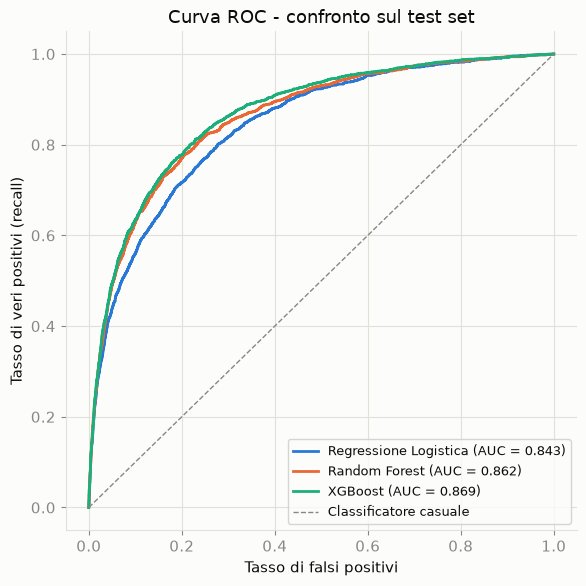

In [9]:
MODELS = {
    'Regressione Logistica': (proba_logit, COLOR_LOGIT),
    'Random Forest': (proba_rf, COLOR_RF),
    'XGBoost': (proba_xgb, COLOR_XGB),
}

fig, ax = plt.subplots(figsize=(6, 6))
for name, (proba, color) in MODELS.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], color=MUTED_COLOR, linestyle='--', linewidth=1, label='Classificatore casuale')
ax.set_xlabel('Tasso di falsi positivi')
ax.set_ylabel('Tasso di veri positivi (recall)')
ax.set_title('Curva ROC - confronto sul test set')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
rows = []
for name, (proba, _) in MODELS.items():
    pred = (proba >= 0.5).astype(int)
    rows.append({
        'modello': name,
        'AUC_test': roc_auc_score(y_test, proba),
        'AUC_cv_train_mean': {
            'Regressione Logistica': np.nan,
            'Random Forest': cv_auc_rf.mean(),
            'XGBoost': cv_auc_xgb.mean(),
        }[name],
        'AUC_cv_train_std': {
            'Regressione Logistica': np.nan,
            'Random Forest': cv_auc_rf.std(),
            'XGBoost': cv_auc_xgb.std(),
        }[name],
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
    })

comparison_metrics = pd.DataFrame(rows).set_index('modello')
comparison_metrics.round(4)

,AUC_test,AUC_cv_train_mean,AUC_cv_train_std,precision,recall,f1
modello,,,,,,
Regressione Logistica,0.8431,NaN,NaN,0.6254,0.0883,0.1547
Random Forest,0.8618,0.8570,0.0039,0.6079,0.1771,0.2742
XGBoost,0.8686,0.8631,0.0056,0.5792,0.2080,0.3061


*(la regressione logistica non ha una CV a 5 fold in questo notebook: il notebook 03 l'ha già
valutata con lo split train/test singolo; la CV qui è richiesta solo per i due modelli nuovi. Le
metriche precision/recall/F1 sono calcolate alla soglia standard 0,5 per tutti e tre, per un
confronto diretto — la sensibilità alla soglia è già stata discussa in dettaglio nel notebook 03.)*

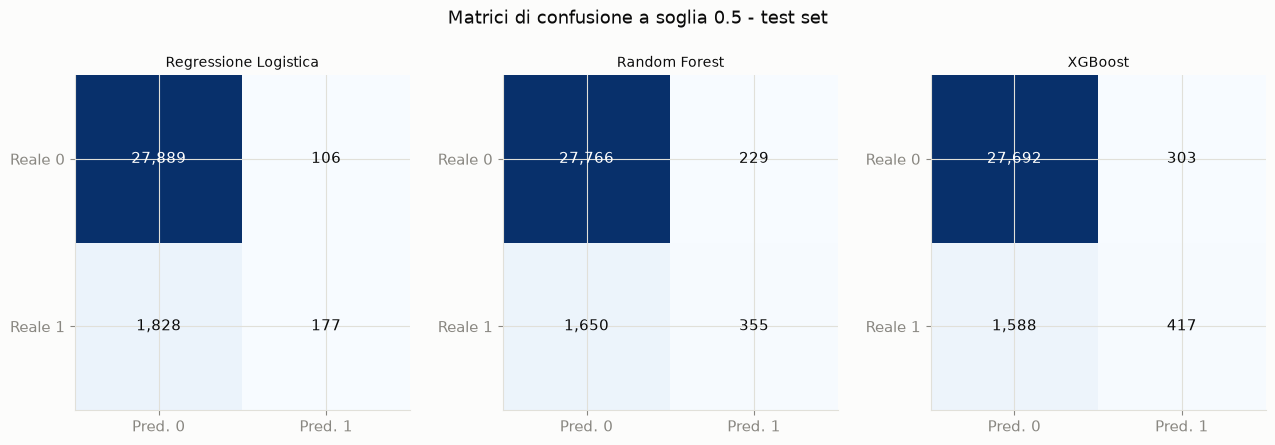

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (name, (proba, _)) in zip(axes, MODELS.items()):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred. 0', 'Pred. 1']); ax.set_yticklabels(['Reale 0', 'Reale 1'])
    ax.set_title(name, fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else TEXT_COLOR, fontsize=11)
fig.suptitle('Matrici di confusione a soglia 0.5 - test set', y=1.02)
plt.tight_layout()
plt.show()

## 7. Feature importance: Random Forest e XGBoost vs odds ratio della regressione logistica

Random Forest e XGBoost restituiscono un'importanza relativa per variabile (impurity/gain, valori
positivi che sommano a 1), non direzionale: non dicono se una variabile aumenta o riduce il
rischio, solo quanto contribuisce alle decisioni del modello. Confrontiamo il **ranking** di
importanza con quello ottenuto nel notebook 03 (odds ratio scalati per IQR o per unità dove l'IQR è
degenere — stessa logica di confronto già introdotta lì).

In [12]:
delinq_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
]
BINARY_FLAGS = ['MonthlyIncome_mancante', 'NumberOfDependents_mancante']

logit_scaled_effect = {}
for var in FEATURES:
    coef = logit_result.params[var]
    if var in BINARY_FLAGS or var in delinq_cols:
        logit_scaled_effect[var] = abs(coef)  # per-unit log-odds, stessa scala per queste
    else:
        iqr = X_train[var].quantile(0.75) - X_train[var].quantile(0.25)
        logit_scaled_effect[var] = abs(coef * iqr)

importance_df = pd.DataFrame({
    'LogReg_effetto_scalato': logit_scaled_effect,
    'RandomForest_importance': dict(zip(FEATURES, rf.feature_importances_)),
    'XGBoost_importance_gain': dict(zip(FEATURES, xgb.feature_importances_)),
})
importance_df['LogReg_rank'] = importance_df['LogReg_effetto_scalato'].rank(ascending=False).astype(int)
importance_df['RandomForest_rank'] = importance_df['RandomForest_importance'].rank(ascending=False).astype(int)
importance_df['XGBoost_rank'] = importance_df['XGBoost_importance_gain'].rank(ascending=False).astype(int)

importance_df.sort_values('RandomForest_importance', ascending=False).round(4)

,LogReg_effetto_scalato,RandomForest_importance,XGBoost_importance_gain,LogReg_rank,RandomForest_rank,XGBoost_rank
RevolvingUtilizationOfUnsecuredLines,1.2262,0.1965,0.1560,1,1,4
NumberOfTimes90DaysLate,0.3077,0.1722,0.3737,4,2,1
DebtRatio,0.0001,0.1238,0.0173,12,3,10
MonthlyIncome,0.0946,0.1070,0.0175,10,4,9
age,0.3300,0.0959,0.0222,3,5,7
NumberOfTime60-89DaysPastDueNotWorse,0.2094,0.0908,0.1620,6,6,2
NumberOfTime30-59DaysPastDueNotWorse,0.3422,0.0830,0.1570,2,7,3
NumberOfOpenCreditLinesAndLoans,0.1808,0.0707,0.0195,7,8,8
NumberOfDependents,0.0626,0.0284,0.0146,11,9,11
NumberRealEstateLoansOrLines,0.1696,0.0255,0.0277,8,10,5


**Convergenze.** Tutti e tre i modelli concordano su un nucleo comune: `RevolvingUtilizationOfUnsecuredLines`
e le colonne di ritardo pagamenti sono sempre tra le prime posizioni, mai tra le ultime — un segnale
robusto, confermato da tre algoritmi con logiche di stima completamente diverse (massima
verosimiglianza lineare, alberi bagged, boosting sequenziale). È esattamente il tipo di conferma
incrociata che dà fiducia in un risultato.

**Discrepanze interessanti:**

- **`age`** è, insieme a `NumberOfTime30-59DaysPastDueNotWorse`, subito dietro
  `RevolvingUtilizationOfUnsecuredLines` nella regressione logistica (rank 3 e 2, valori
  dell'effetto scalato quasi identici: 0,330 contro 0,342 — sostanzialmente appaiate), ma scivola a
  metà classifica in Random Forest (rank 5) e quasi in fondo in XGBoost (rank 7). Interpretazione
  plausibile: la relazione tra età e rischio è in gran parte **lineare/monotona** (più il cliente è
  giovane, più rischia, in modo abbastanza graduale) — esattamente il tipo di segnale che un
  coefficiente lineare cattura in modo efficiente, mentre l'importanza basata su split/guadagno
  degli alberi premia le variabili che generano suddivisioni nette e ad alta informazione
  (tipicamente i conteggi di ritardo, quasi sempre zero con pochi valori positivi molto
  informativi), non le relazioni smussate su tutto il range.
- **`DebtRatio`** è quasi irrilevante nella regressione logistica (coerente con il notebook 02, che
  l'aveva già segnalata come "significativa solo sulla carta"), ma **Random Forest la mette al
  terzo posto**. Questo probabilmente riflette un bias noto della feature importance basata su
  impurity/Gini di Random Forest: tende a sovrastimare le variabili continue con molti valori
  distinti (offrono più punti di split candidati), indipendentemente dal loro reale potere
  predittivo. XGBoost — che usa il guadagno (gain) invece dell'impurity — non mostra lo stesso
  effetto per `DebtRatio` (quasi ultima posizione, coerente con logistica e notebook 02). Questo è
  un caso concreto in cui **conviene fidarsi della convergenza tra più fonti** (logistica + XGBoost)
  piuttosto che di una singola misura di importanza.
- **`NumberOfTimes90DaysLate`** domina XGBoost (37% del gain totale, primo posto netto) più di
  quanto non faccia negli altri due modelli: XGBoost, allenato in sequenza per correggere gli errori
  residui, tende a concentrare il guadagno sulle variabili più immediatamente separatrici — qui, il
  segnale più grave e diretto di insolvenza pregressa.

## 8. Quale modello portare avanti?

In [13]:
comparison_metrics[['AUC_test', 'precision', 'recall', 'f1']].round(4).sort_values('AUC_test', ascending=False)

,AUC_test,precision,recall,f1
modello,,,,
XGBoost,0.8686,0.5792,0.2080,0.3061
Random Forest,0.8618,0.6079,0.1771,0.2742
Regressione Logistica,0.8431,0.6254,0.0883,0.1547


**XGBoost vince su tutti i fronti misurati**: AUC test più alta (0,869 contro 0,862 di Random
Forest e 0,843 della regressione logistica), F1 più alto (0,306) e recall più alto (0,208) alla
stessa soglia 0,5 — Random Forest ha una precision leggermente superiore (0,608 contro 0,579), ma
il vantaggio di XGBoost sulle altre metriche è più ampio. La classifica è anche coerente con la CV
a 5 fold sul training set (XGBoost 0,863 ± 0,006 contro Random Forest 0,857 ± 0,004): non è un
risultato dovuto al caso di un singolo split.

**Il guadagno in AUC (+2,5 punti percentuali rispetto alla regressione logistica) giustifica la
minore interpretabilità diretta?** Nel credito al consumo la risposta non è solo tecnica:

- Un guadagno di 2-3 punti di AUC è **reale e non trascurabile** in un contesto dove anche piccoli
  miglioramenti nella discriminazione del rischio si traducono in perdite attese minori su un
  portafoglio di centinaia di migliaia di clienti (lo quantificheremo nel notebook
  `06_expected_loss`).
- La regressione logistica resta però l'unica, tra le tre, che fornisce **direttamente** un odds
  ratio interpretabile per ciascuna variabile, con tanto di intervallo di confidenza — utile
  quando serve giustificare una decisione di credito a un cliente o a un regolatore (in molte
  giurisdizioni il rifiuto di credito richiede una motivazione specifica, non solo un punteggio).
  XGBoost e Random Forest non offrono questo per costruzione.
- Non è però un aut-aut: il prossimo notebook (`05_shap`) applica **SHAP** proprio per recuperare
  una spiegabilità locale, per singolo cliente, anche per un modello "black-box" come XGBoost.
  Per questo portiamo avanti **XGBoost** (la performance migliore) sapendo di poter comunque
  rispondere, dopo il notebook 05, alla domanda "perché il modello ha assegnato questo rischio a
  *questo* cliente" — non solo "quali variabili contano in media".

In [14]:
BEST_MODEL_NAME = 'XGBoost'
best_model = xgb

X_full = df[FEATURES]
X_full_dmatrix_ok = X_full  # XGBClassifier accetta direttamente un DataFrame
pd_full_best = best_model.predict_proba(X_full)[:, 1]

output_best = pd.DataFrame({
    'CustomerID': df.index,
    'PD': pd_full_best,
    'SeriousDlqin2yrs': df[TARGET].values,
})

print(f"Modello scelto: {BEST_MODEL_NAME}")
print(f"PD media stimata: {output_best['PD'].mean():.4f}  |  tasso di default osservato: {df[TARGET].mean():.4f}")

Modello scelto: XGBoost
PD media stimata: 0.0669  |  tasso di default osservato: 0.0668


In [15]:
OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'probabilita_insolvenza.csv'
output_best.to_csv(OUTPUT_PATH, index=False)
print(f"Salvato: {OUTPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}  ({len(output_best):,} righe)")
print("Nota: questo file sostituisce la versione prodotta dal notebook 03 (sola regressione")
print("logistica) con le PD del modello XGBoost, che portiamo avanti per SHAP ed Expected Loss.")

Salvato: data/processed/probabilita_insolvenza.csv  (149,999 righe)
Nota: questo file sostituisce la versione prodotta dal notebook 03 (sola regressione
logistica) con le PD del modello XGBoost, che portiamo avanti per SHAP ed Expected Loss.


## Conclusioni

- Lo split train/test del notebook 03 è stato riprodotto **esattamente** (verificato, non solo
  assunto), permettendo un confronto equo tra i tre modelli sugli stessi dati.
- Tutti e tre i modelli sono stati allenati **senza ribilanciare le classi**, la stessa strategia
  del notebook 03, per non confondere l'effetto dell'algoritmo con quello del trattamento dello
  sbilanciamento.
- **XGBoost** ottiene l'AUC più alta sia in cross-validation (0,863 ± 0,006) sia sul test set
  (0,869), confermata da F1 e recall superiori a parità di soglia — è il modello che portiamo
  avanti.
- La feature importance conferma il nucleo di variabili già emerso nei notebook precedenti
  (`RevolvingUtilizationOfUnsecuredLines`, ritardi di pagamento), ma con differenze di ranking
  spiegabili (linearità del segnale per `age`, bias noto dell'importanza impurity-based di Random
  Forest per `DebtRatio`) piuttosto che vere contraddizioni.
- Le PD del modello XGBoost sono salvate in `data/processed/probabilita_insolvenza.csv`, pronte per
  `05_shap` (spiegabilità locale) e `06_expected_loss` (impatto economico).